# LightGBM (+ XGBoost) · Model building (Issue #13)

## Where this notebook sits
```
03_clean_missing_outliers ─► 04_feature_engineering ─► features_{train,test}.parquet ──┐
                                                    └─► 05_encode_scale ─► model_ready_*   │  (logistic regression input)
06_ml_algorithms_exploration (Edem, #11) ─► shortlist (#12): LightGBM, LogReg, Random forest │
07_drift_and_baseline (Krish): untuned HistGB baseline, AUC 0.768, inclusion gap             │
                                                                                             ▼
model_building/lightgbm.ipynb   ◄── this notebook (#13, gradient boosting)
        ▼
Task #4 candidate model choice (group) ─► #14 hyper-parameter tuning (Skylar) ─► decision policy / Streamlit
```

**Input:** `data/processed/features_{train,test}.parquet` (from notebook 04). Run `python run_pipeline.py` or notebooks 03 → 04 first.
**Output:** `notebooks/model_building/artifacts/`: tuned settings, results tables, saved models and predictions for #4 and #14.

### How this differs from Krish's notebook 07
Krish's model answered *"does the inclusion gap exist?"* This notebook builds gradient boosting as a **candidate model**:
LightGBM (the #12 shortlist) and XGBoost as a paired comparison. Both are tuned without overfitting, scored on every metric
the challenge uses (per segment), and checked for probability accuracy. It also tests the two fixes Edem's exploration flagged
for the thin-file gap: **per-segment calibration** and **recency weighting**.

### Why the raw feature file, not `model_ready_*`
Trees don't need scaling, and they handle missing values natively, learning which way "missing" should go at each split.
`model_ready_*` replaces "no credit history" with a median, which hides exactly the thin-file signal we care about.
Same choice as Krish's notebook 07, so results are directly comparable.

## Read this first: the notebook in two minutes

**The problem.** American Express wants to approve more people with little or no credit history ("**thin-file**", ~30% of applicants)
without losing money. A model predicts each applicant's **probability of default (PD)**; anyone below 20% is approved, because at
+$2,000 per repaid loan and −$8,000 per default, 20% is the break-even point.

**What this notebook does (Task #3 / Issue #13, gradient boosting).**
1. Builds two gradient-boosting models, **LightGBM** and **XGBoost**. Both are collections of many small decision trees, each one correcting the last.
2. Chooses their settings carefully so they **don't overfit**: they're learned on older weeks, chosen on middle weeks, and tested once on the newest weeks.
3. Compares **LightGBM alone** with an **ensemble** (the average of both models).
4. Reports accuracy and F1 (as Task #3 asks), plus the metrics the challenge is graded on: AUC, LogLoss, Brier, profit and the inclusion
   gap, overall and for thin-file vs established applicants.
5. Tests two fixes for the unfair treatment of thin-file applicants: **per-segment calibration** and **recency weighting**.

**What we found** (details in §13):
- Gradient boosting beats the logistic-regression baseline (AUC 0.768 vs 0.760, +$2.8M profit).
- The exact settings barely matter, and the ensemble adds nothing, so **LightGBM alone** is enough.
- The real problem is that the model **over-estimates thin-file risk** because their risk has fallen over time. Correcting the
  probabilities per segment **cuts the inclusion gap from 31.8 to 13.6 points and raises profit by $1.9M.**

**How to read it.** Each section starts with a short explanation, every code cell has a one-line comment saying what it does, and key
results are followed by a "What this shows" note. To re-run it, first run `python run_pipeline.py` from the repo root, then run all cells (~20 min).

### Glossary
| Term | Meaning |
|---|---|
| **PD** | predicted probability of default (0-1) for one applicant |
| **Thin-file / established** | no credit-bureau history / has credit-bureau history |
| **Train / tune / valid weeks** | 0-67 to learn, 68-79 to choose settings, 80-91 to test once at the end |
| **Overfitting** | memorising the training weeks instead of learning patterns that hold on new weeks |
| **Early stopping** | stop adding trees as soon as the tune weeks stop improving, a guard against overfitting |
| **AUC** | how well the model *ranks* defaulters above repayers (0.5 = coin flip, 1 = perfect) |
| **LogLoss / Brier** | how accurate the *probabilities* are (lower = better) |
| **Calibration** | whether a predicted 20% really means 20% of those people default |
| **Inclusion gap** | approval rate of established repayers minus approval rate of thin-file repayers (0 = equal treatment) |
| **Ensemble (soft voting)** | averaging the probabilities of several models |
| **Recency weighting** | letting recent weeks count more when the model learns |
| **SHAP** | how much each feature pushed one applicant's prediction up or down |

In [1]:
# Setup: libraries, folder paths and the constants used everywhere (time split, profit rules).

from pathlib import Path
import json
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import xgboost as xgb
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, brier_score_loss, f1_score,
                             log_loss, roc_auc_score)

warnings.filterwarnings("ignore", message="Overriding the parameters from Reference Dataset")

ROOT = Path.cwd().parent.parent          # notebooks/model_building -> repo root
PROCESSED = ROOT / "data" / "processed"
ART = Path.cwd() / "artifacts"           # everything this notebook saves lives here
ART.mkdir(exist_ok=True)

SEED = 42
N_THREADS = os.cpu_count()

# Time split (same weeks as notebooks 04-07):
#   weeks  0-67 -> train      (models learn here)
#   weeks 68-79 -> tune       (early stopping, hyper-parameter choice, calibration)
#   weeks 80-91 -> valid      (scored ONCE per final model, never used to choose anything)
#   weeks 92-107 = test set, labels hidden (solution.csv is never opened)
TUNE_START_WEEK = 68
VALID_START_WEEK = 80

# Challenge economics: +$2,000 per repaid approved loan, -$8,000 per defaulted approved loan.
GAIN, LOSS = 2_000, -8_000
CUTOFF = 0.20                            # break-even default probability: 2000 - 10000 p = 0  ->  p = 0.2

## 1. Load data and build the splits

`thin_file` is **not** a model feature (same as notebook 07): everyone is scored by the same rules. It is kept to report
metrics per segment, and in §8 to calibrate per segment.

In [2]:
# Load the feature table from notebook 04 and split the rows by week into train / tune / valid.

train_df = pd.read_parquet(PROCESSED / "features_train.parquet")
test_df = pd.read_parquet(PROCESSED / "features_test.parquet")

NOT_FEATURES = ["case_id", "target", "WEEK_NUM", "thin_file", "date_decision", "birth_259D"]
FEATURES = [c for c in train_df.columns if c not in NOT_FEATURES]
CAT_COLS = [c for c in FEATURES if not pd.api.types.is_numeric_dtype(train_df[c])]
# Fix the category list once so train, valid and test all use identical category codes.
CATEGORIES = {c: sorted(train_df[c].dropna().unique()) for c in CAT_COLS}


def prepare(df):
    X = df[FEATURES].copy()
    for c in CAT_COLS:
        X[c] = pd.Categorical(X[c], categories=CATEGORIES[c])
    return X


X_all, y_all = prepare(train_df), train_df["target"].to_numpy()
thin_all, week = train_df["thin_file"].to_numpy(), train_df["WEEK_NUM"].to_numpy()
X_test = prepare(test_df)

part = np.select([week < TUNE_START_WEEK, week < VALID_START_WEEK], ["train", "tune"], "valid")
TR, TU, VA = part == "train", part == "tune", part == "valid"
FIT = TR | TU                                   # weeks 0-79, used to retrain final models

print(f"{len(FEATURES)} features ({len(CAT_COLS)} categorical: {CAT_COLS})")
pd.DataFrame({
    "weeks": ["0-67", "68-79", "80-91"],
    "rows": [TR.sum(), TU.sum(), VA.sum()],
    "default rate %": [y_all[m].mean() * 100 for m in (TR, TU, VA)],
    "thin-file default rate %": [y_all[m & (thin_all == 1)].mean() * 100 for m in (TR, TU, VA)],
}, index=["train", "tune", "valid"]).round(2)

55 features (4 categorical: ['education_927M', 'maritalstatus_703M', 'description_5085714M', 'housingtype_772M'])


,weeks,rows,default rate %,thin-file default rate %
train,0-67,739183,19.72,27.45
tune,68-79,130376,17.91,21.22
valid,80-91,130441,17.36,19.81


Thin-file default risk keeps falling across the three windows. Every model trained on older weeks will therefore tend to
**over-estimate** thin-file risk on later weeks; that's the drift Krish quantified in notebook 07.

## 2. One evaluation function for every model

Every model is scored the same way, on the same validation weeks:
- **Ranking:** AUC overall / thin-file / established (higher is better)
- **Probability quality:** LogLoss and Brier (lower is better), plus *predicted minus actual* default rate per segment (0 = honest)
- **Task #3 metrics at the 20% cutoff:** accuracy and F1 (class 1 = default, so a "positive" is a decline). Note that approving
  everyone already scores ~83% accuracy here, so accuracy alone is misleading.
- **Decision quality at the 20% cutoff:** approval rate, default rate among approved, profit, and the **inclusion gap**
  (approval rate among repayers: established minus thin-file)
- **Gap at 70% approval:** Krish's notebook-07 setting, for a like-for-like comparison

In [3]:
# evaluate(): turns predicted default probabilities into every metric the challenge uses.

def evaluate(y, p, thin, cutoff=CUTOFF):
    y, p, thin = np.asarray(y), np.asarray(p), np.asarray(thin) == 1
    est = ~thin
    decline = p >= cutoff
    approve = ~decline
    repaid = y == 0

    def approval_gap(appr):
        return (appr[repaid & est].mean() - appr[repaid & thin].mean()) * 100

    approve_70 = p < np.quantile(p, 0.70)
    return {
        "AUC": roc_auc_score(y, p),
        "AUC thin": roc_auc_score(y[thin], p[thin]),
        "AUC est": roc_auc_score(y[est], p[est]),
        "LogLoss": log_loss(y, p),
        "LogLoss thin": log_loss(y[thin], p[thin]),
        "Brier": brier_score_loss(y, p),
        "Pred-actual thin pp": (p[thin].mean() - y[thin].mean()) * 100,
        "Pred-actual est pp": (p[est].mean() - y[est].mean()) * 100,
        "Accuracy@20%": accuracy_score(y, decline),
        "F1@20%": f1_score(y, decline),
        "Approval %": approve.mean() * 100,
        "Default % approved": y[approve].mean() * 100,
        "Profit $M": (GAIN * (approve & repaid).sum() + LOSS * (approve & ~repaid).sum()) / 1e6,
        "Approved repayers est %": approve[repaid & est].mean() * 100,
        "Approved repayers thin %": approve[repaid & thin].mean() * 100,
        "Gap@20% pp": approval_gap(approve),
        "Gap@70% approval pp": approval_gap(approve_70),
    }


results = {}   # model name -> metrics on weeks 80-91

## 3. Reference models

1. **Logistic regression** on the scaled `model_ready` files (team baseline, notebook 05), re-scored here with the full metric set.
2. **LightGBM with Krish-style settings** (learning rate 0.05, 300 trees, no tuning) on weeks 0-79. It should land near Krish's
   HistGB 0.768. If it does, this notebook's setup is consistent with the team's.

In [4]:
# Two reference points to beat: logistic regression (team baseline) and LightGBM with default settings.

fit_mr = pd.read_parquet(PROCESSED / "model_ready_fit.parquet")
val_mr = pd.read_parquet(PROCESSED / "model_ready_valid.parquet")
mr_meta = ["case_id", "target", "WEEK_NUM", "thin_file"]
logreg = LogisticRegression(max_iter=1000).fit(fit_mr.drop(columns=mr_meta), fit_mr["target"])
p_logreg = logreg.predict_proba(val_mr.drop(columns=mr_meta))[:, 1]
results["LogReg (05 baseline)"] = evaluate(val_mr["target"], p_logreg, val_mr["thin_file"])
del fit_mr, val_mr

t = time.time()
lgb_ref = lgb.train(
    {"objective": "binary", "learning_rate": 0.05, "verbose": -1, "num_threads": N_THREADS, "seed": SEED},
    lgb.Dataset(X_all[FIT], y_all[FIT]), num_boost_round=300,
)
p_ref = lgb_ref.predict(X_all[VA])
results["LightGBM untuned (Krish-style)"] = evaluate(y_all[VA], p_ref, thin_all[VA])
print(f"untuned LightGBM trained in {time.time() - t:.0f}s")
pd.DataFrame(results).T[["AUC", "AUC thin", "AUC est", "LogLoss", "Brier"]].round(4)

untuned LightGBM trained in 12s


,AUC,AUC thin,AUC est,LogLoss,Brier
LogReg (05 baseline),0.7597,0.7082,0.7856,0.3980,0.1241
LightGBM untuned (Krish-style),0.7682,0.7064,0.7944,0.3924,0.1226


**What this shows:** even with default settings, LightGBM beats logistic regression (AUC 0.768 vs 0.760, LogLoss 0.392 vs 0.398).
It matches Krish's HistGB (0.768), so this notebook's setup is consistent with the team's. Thin-file AUC is about the same (~0.707) for both.

## 4. Tune LightGBM without overfitting

**Method: random search + early stopping, judged on the tune weeks (68-79) only.**
- Each candidate trains on weeks 0-67 and keeps adding trees until **tune LogLoss** stops improving for 100 rounds. Early
  stopping chooses the number of trees, the main overfitting knob.
- The other settings control how complex each tree is and how much randomness is used:

| Setting | What it controls | Range searched |
|---|---|---|
| `num_leaves` | complexity of each tree | 15, 31, 63, 127 |
| `min_child_samples` | smallest group a leaf may contain (bigger = smoother) | 50-3000 (log scale) |
| `feature_fraction` | share of features each tree may use | 0.5-1.0 |
| `bagging_fraction` | share of rows each tree sees | 0.6-1.0 |
| `lambda_l2` | penalty on extreme leaf values | 0.1-50 (log scale) |

- **Learning rate is fixed at 0.05.** A smaller rate trades training time for tiny gains, and is a knob for #14.
- **Choice metric: tune LogLoss**, not AUC. The profit rule uses the probabilities themselves.
- **Simplicity rule:** settings within 0.0003 LogLoss of the best are treated as ties (a difference that small is noise on
  ~160k rows), and among ties the **simplest** model wins (fewest leaves, then largest leaf size). That deliberately leans away from overfitting.
- `scale_pos_weight` / `is_unbalance` are **not** used: a 19% default rate isn't severe imbalance, and re-weighting classes
  distorts the probabilities the profit calculation depends on.

In [5]:
# Try 30 random LightGBM settings; each one stops adding trees once the tune weeks stop improving.

N_LGB_TRIALS = 30
TIE_TOLERANCE = 0.0003
rng = np.random.default_rng(SEED)

LGB_BASE = {"objective": "binary", "learning_rate": 0.05, "bagging_freq": 1, "verbose": -1,
            "num_threads": N_THREADS, "seed": SEED, "feature_pre_filter": False}

# Build the binned datasets once and reuse them for every trial (much faster).
d_train = lgb.Dataset(X_all[TR], y_all[TR], params={"feature_pre_filter": False}, free_raw_data=False)
d_tune = lgb.Dataset(X_all[TU], y_all[TU], reference=d_train)


def sample_lgb():
    return {
        "num_leaves": int(rng.choice([15, 31, 63, 127])),
        "min_child_samples": int(np.exp(rng.uniform(np.log(50), np.log(3000)))),
        "feature_fraction": round(float(rng.uniform(0.5, 1.0)), 2),
        "bagging_fraction": round(float(rng.uniform(0.6, 1.0)), 2),
        "lambda_l2": round(float(np.exp(rng.uniform(np.log(0.1), np.log(50)))), 3),
    }


lgb_trials, t0 = [], time.time()
for i in range(N_LGB_TRIALS):
    hp = sample_lgb()
    booster = lgb.train({**LGB_BASE, **hp}, d_train, num_boost_round=5000, valid_sets=[d_tune],
                        callbacks=[lgb.early_stopping(100, verbose=False)])
    n = booster.best_iteration
    p_tr = booster.predict(X_all[TR], num_iteration=n)
    p_tu = booster.predict(X_all[TU], num_iteration=n)
    lgb_trials.append({**hp, "trees": n,
                       "train_logloss": log_loss(y_all[TR], p_tr), "tune_logloss": log_loss(y_all[TU], p_tu),
                       "tune_auc": roc_auc_score(y_all[TU], p_tu)})
print(f"{N_LGB_TRIALS} LightGBM trials in {(time.time() - t0) / 60:.1f} min")

lgb_tuning = pd.DataFrame(lgb_trials)
lgb_tuning["overfit_gap"] = lgb_tuning["tune_logloss"] - lgb_tuning["train_logloss"]
lgb_tuning = lgb_tuning.sort_values("tune_logloss").reset_index(drop=True)
lgb_tuning.head(10).round(4)

30 LightGBM trials in 8.1 min


,num_leaves,min_child_samples,feature_fraction,bagging_fraction,lambda_l2,trees,train_logloss,tune_logloss,tune_auc,overfit_gap
0,63,79,0.83,0.79,3.354,144,0.4062,0.3960,0.7729,-0.0101
1,15,660,0.68,0.64,0.208,578,0.4072,0.3961,0.7729,-0.0111
2,31,1222,0.73,0.83,0.238,240,0.4077,0.3961,0.7729,-0.0117
3,31,350,0.61,0.87,1.513,273,0.4070,0.3961,0.7728,-0.0109
4,15,189,0.69,0.79,0.325,701,0.4058,0.3961,0.7728,-0.0097
5,31,293,0.81,0.83,5.674,162,0.4089,0.3961,0.7729,-0.0128
6,31,307,0.61,0.82,0.149,328,0.4060,0.3961,0.7728,-0.0099
7,31,244,0.64,0.87,0.238,275,0.4069,0.3961,0.7728,-0.0107
8,63,70,0.71,0.62,2.154,119,0.4072,0.3961,0.7728,-0.0111
9,31,94,0.84,0.90,40.858,151,0.4093,0.3961,0.7729,-0.0132


In [6]:
# Pick the winner: best tune LogLoss, but the simplest settings among near-ties.

def pick_simplest(tuning, complexity_cols, ascending):
    """Best tune LogLoss, but among near-ties choose the simplest settings."""
    ties = tuning[tuning["tune_logloss"] <= tuning["tune_logloss"].min() + TIE_TOLERANCE]
    return ties.sort_values(complexity_cols, ascending=ascending).iloc[0], len(ties)


lgb_best, n_ties = pick_simplest(lgb_tuning, ["num_leaves", "min_child_samples"], [True, False])
LGB_PARAMS = {**LGB_BASE, **{k: lgb_best[k] for k in ["num_leaves", "min_child_samples", "feature_fraction",
                                                       "bagging_fraction", "lambda_l2"]}}
LGB_PARAMS["num_leaves"] = int(LGB_PARAMS["num_leaves"])
LGB_PARAMS["min_child_samples"] = int(LGB_PARAMS["min_child_samples"])
LGB_TREES = int(lgb_best["trees"])
print(f"{n_ties} settings tied within {TIE_TOLERANCE}; chose the simplest:")
lgb_best.round(4)

28 settings tied within 0.0003; chose the simplest:


num_leaves             15.0000
min_child_samples    2013.0000
feature_fraction        0.7300
bagging_fraction        0.6800
lambda_l2               0.6700
trees                 280.0000
train_logloss           0.4096
tune_logloss            0.3962
tune_auc                0.7727
overfit_gap            -0.0134
Name: 20, dtype: float64

**How to read the tuning table:** each row is one tried setting. `trees` is where early stopping stopped; `tune_logloss` is the score
used to choose (lower is better); `overfit_gap` compares tune and train error. The top rows differ only in the 4th decimal place, so the
search is flat: almost any reasonable setting works. That's why the simplest one was picked.

### Is the chosen LightGBM overfitting?
Retrain the chosen settings while tracking LogLoss on **both** windows. A healthy model shows the tune curve flattening (not
rising) where early stopping cuts it off, with a modest train-tune gap. A model that keeps improving on train while getting worse
on tune is overfitting.

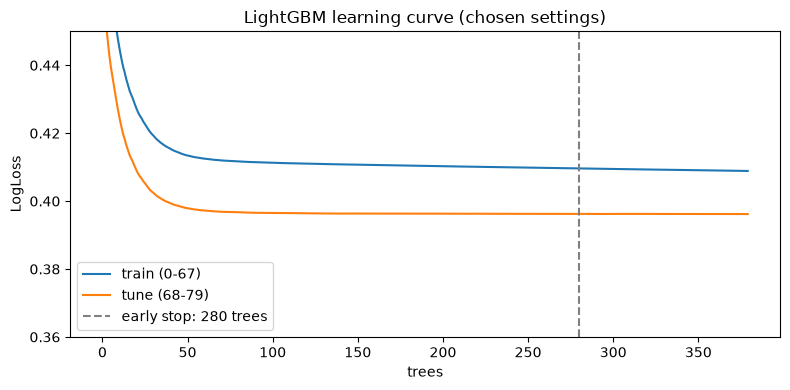

train-tune LogLoss gap at the stopping point: -0.0134


In [7]:
# Retrain the chosen settings and plot train vs tune error as trees are added (overfitting check).

curves = {}
lgb_early = lgb.train(LGB_PARAMS, d_train, num_boost_round=5000,
                      valid_sets=[d_train, d_tune], valid_names=["train (0-67)", "tune (68-79)"],
                      callbacks=[lgb.early_stopping(100, verbose=False), lgb.record_evaluation(curves)])

fig, ax = plt.subplots(figsize=(8, 4))
for name, rec in curves.items():
    ax.plot(rec["binary_logloss"], label=name)
ax.axvline(lgb_early.best_iteration, color="grey", ls="--", label=f"early stop: {lgb_early.best_iteration} trees")
ax.set(xlabel="trees", ylabel="LogLoss", title="LightGBM learning curve (chosen settings)", ylim=(0.36, 0.45))
ax.legend(); plt.tight_layout(); plt.show()

gap = curves["tune (68-79)"]["binary_logloss"][lgb_early.best_iteration - 1] - curves["train (0-67)"]["binary_logloss"][lgb_early.best_iteration - 1]
print(f"train-tune LogLoss gap at the stopping point: {gap:.4f}")

**Reading the curve:** the tune curve flattens by ~100 trees and never turns upward, so there's no overfitting. The tune LogLoss is *lower* than
train because weeks 68-79 have a lower default rate (17.9% vs 19.7%), which makes them easier to predict. It isn't a sign of a problem.
The chosen settings are the most conservative in the search: small trees (15 leaves) and a large minimum leaf size (~2,000 applicants).

**28 of 30 settings tied** within 0.0003 LogLoss. On this data, hyper-parameters barely matter: the signal is mostly simple, so
there is little for a more complex model to find. Expect #14 (tuning) to gain very little beyond these settings.

## 5. Tune XGBoost the same way (the paired comparison)

XGBoost grows trees **level by level** (controlled by `max_depth`), while LightGBM grows **leaf by leaf** (controlled by `num_leaves`).
Same rules: train 0-67, early stopping and choice on the tune weeks, LogLoss, simplest among ties. Fewer trials, because XGBoost is ~2.5× slower here.

| Setting | Range searched |
|---|---|
| `max_depth` | 3, 4, 5, 6, 8 |
| `min_child_weight` (≈ minimum leaf size, in hessian units) | 1-200 (log scale) |
| `subsample` / `colsample_bytree` | 0.6-1.0 / 0.5-1.0 |
| `reg_lambda` | 0.1-50 (log scale) |

In [8]:
# Same tuning procedure for XGBoost (12 random settings), then pick the simplest near-best one.

N_XGB_TRIALS = 12
XGB_BASE = {"tree_method": "hist", "enable_categorical": True, "max_cat_to_onehot": 16, "learning_rate": 0.05,
            "eval_metric": "logloss", "n_jobs": N_THREADS, "random_state": SEED}


def sample_xgb():
    return {
        "max_depth": int(rng.choice([3, 4, 5, 6, 8])),
        "min_child_weight": round(float(np.exp(rng.uniform(np.log(1), np.log(200)))), 2),
        "subsample": round(float(rng.uniform(0.6, 1.0)), 2),
        "colsample_bytree": round(float(rng.uniform(0.5, 1.0)), 2),
        "reg_lambda": round(float(np.exp(rng.uniform(np.log(0.1), np.log(50)))), 3),
    }


xgb_trials, t0 = [], time.time()
for i in range(N_XGB_TRIALS):
    hp = sample_xgb()
    model = xgb.XGBClassifier(**XGB_BASE, **hp, n_estimators=5000, early_stopping_rounds=100)
    model.fit(X_all[TR], y_all[TR], eval_set=[(X_all[TU], y_all[TU])], verbose=False)
    p_tr = model.predict_proba(X_all[TR])[:, 1]
    p_tu = model.predict_proba(X_all[TU])[:, 1]
    xgb_trials.append({**hp, "trees": model.best_iteration + 1,
                       "train_logloss": log_loss(y_all[TR], p_tr), "tune_logloss": log_loss(y_all[TU], p_tu),
                       "tune_auc": roc_auc_score(y_all[TU], p_tu)})
print(f"{N_XGB_TRIALS} XGBoost trials in {(time.time() - t0) / 60:.1f} min")

xgb_tuning = pd.DataFrame(xgb_trials)
xgb_tuning["overfit_gap"] = xgb_tuning["tune_logloss"] - xgb_tuning["train_logloss"]
xgb_tuning = xgb_tuning.sort_values("tune_logloss").reset_index(drop=True)

xgb_best, n_ties = pick_simplest(xgb_tuning, ["max_depth", "min_child_weight"], [True, False])
XGB_PARAMS = {k: xgb_best[k] for k in ["min_child_weight", "subsample", "colsample_bytree", "reg_lambda"]}
XGB_PARAMS["max_depth"] = int(xgb_best["max_depth"])
XGB_TREES = int(xgb_best["trees"])
print(f"{n_ties} settings tied; chose max_depth={XGB_PARAMS['max_depth']}, {XGB_TREES} trees")
xgb_tuning.head(8).round(4)

12 XGBoost trials in 8.2 min
9 settings tied; chose max_depth=3, 562 trees


,max_depth,min_child_weight,subsample,colsample_bytree,reg_lambda,trees,train_logloss,tune_logloss,tune_auc,overfit_gap
0,5,10.03,1.00,0.95,10.483,298,0.4079,0.3960,0.7729,-0.0118
1,5,47.08,0.91,0.55,29.668,515,0.4064,0.3961,0.7727,-0.0103
2,4,160.57,0.79,0.89,0.167,491,0.4089,0.3961,0.7728,-0.0127
3,5,1.12,0.93,0.95,0.239,151,0.4094,0.3962,0.7728,-0.0132
4,4,72.41,0.73,0.98,0.610,417,0.4089,0.3962,0.7727,-0.0128
5,4,1.78,0.87,0.64,6.022,483,0.4085,0.3962,0.7726,-0.0123
6,5,4.11,0.73,0.76,1.530,281,0.4076,0.3962,0.7727,-0.0114
7,8,113.72,0.81,0.66,12.124,145,0.4059,0.3963,0.7725,-0.0097


## 6. Final models: retrain on weeks 0-79 and score weeks 80-91 once

The chosen settings are retrained on all fit weeks (0-79) with the tree count found by early stopping, then scored on the
untouched validation weeks. The **blend** averages the two models' probabilities 50/50 (the ensemble, see §6b). The weight is fixed in advance,
not tuned on validation.

In [9]:
# Retrain both winners on weeks 0-79 and score them on weeks 80-91 (the first time those weeks are used).

t = time.time()
lgb_final = lgb.train(LGB_PARAMS, lgb.Dataset(X_all[FIT], y_all[FIT]), num_boost_round=LGB_TREES)
xgb_final = xgb.XGBClassifier(**XGB_BASE, **XGB_PARAMS, n_estimators=XGB_TREES).fit(X_all[FIT], y_all[FIT])
print(f"final models trained in {time.time() - t:.0f}s")

p_lgb = lgb_final.predict(X_all[VA])
p_xgb = xgb_final.predict_proba(X_all[VA])[:, 1]
p_blend = (p_lgb + p_xgb) / 2

results["LightGBM tuned"] = evaluate(y_all[VA], p_lgb, thin_all[VA])
results["XGBoost tuned"] = evaluate(y_all[VA], p_xgb, thin_all[VA])
results["Ensemble LightGBM+XGBoost"] = evaluate(y_all[VA], p_blend, thin_all[VA])
print(f"LightGBM vs XGBoost prediction correlation: {np.corrcoef(p_lgb, p_xgb)[0, 1]:.4f}")
pd.DataFrame(results).T[["AUC", "AUC thin", "AUC est", "LogLoss", "LogLoss thin", "Brier",
                         "Pred-actual thin pp", "Pred-actual est pp"]].round(4)

final models trained in 42s


LightGBM vs XGBoost prediction correlation: 0.9973


,AUC,AUC thin,AUC est,LogLoss,LogLoss thin,Brier,Pred-actual thin pp,Pred-actual est pp
LogReg (05 baseline),0.7597,0.7082,0.7856,0.3980,0.4673,0.1241,6.4011,-0.0520
LightGBM untuned (Krish-style),0.7682,0.7064,0.7944,0.3924,0.4639,0.1226,5.6011,0.0806
LightGBM tuned,0.7679,0.7065,0.7940,0.3925,0.4637,0.1227,5.5515,0.0389
XGBoost tuned,0.7677,0.7063,0.7941,0.3925,0.4638,0.1226,5.5929,0.0105
Ensemble LightGBM+XGBoost,0.7679,0.7064,0.7942,0.3924,0.4637,0.1226,5.5722,0.0247


**What this shows:** tuned LightGBM and XGBoost land on essentially the same scores as the untuned model, and their predictions are
99.7% correlated. Both still over-predict thin-file risk by ~5.5 points (`Pred-actual thin pp`), while established applicants are almost exact (~0.0).

## 6b. Ensemble learning: LightGBM only vs LightGBM + XGBoost

**Ensemble learning** combines several models so their individual mistakes partly cancel out. Here it's **soft voting**: the
ensemble's default probability is the average of LightGBM's and XGBoost's. Averaging probabilities (instead of votes) keeps a
probability that the 20% cutoff and the profit math can use.

An ensemble only helps if the members make *different* mistakes. LightGBM and XGBoost are close cousins (both gradient-boosted
trees on the same features), so expect high agreement and a small gain. It also costs more: two models to train, tune, explain and maintain.

**Decision rule, fixed before looking at the result.** Recommend the ensemble only if, on weeks 80-91, it
1. lowers LogLoss by more than the tie tolerance (0.0003) **and**
2. does not worsen thin-file AUC or the inclusion gap.

Otherwise, LightGBM alone is the better choice: same quality, half the complexity.

In [10]:
# Head-to-head: LightGBM alone vs the average of LightGBM and XGBoost, judged by a rule set in advance.

head_to_head = pd.DataFrame({
    "LightGBM only": results["LightGBM tuned"],
    "XGBoost only": results["XGBoost tuned"],
    "Ensemble (LightGBM + XGBoost)": results["Ensemble LightGBM+XGBoost"],
}).T[["AUC", "AUC thin", "AUC est", "LogLoss", "LogLoss thin", "Brier", "Profit $M", "Gap@20% pp"]]
diff = head_to_head.loc["Ensemble (LightGBM + XGBoost)"] - head_to_head.loc["LightGBM only"]
head_to_head.loc["Ensemble minus LightGBM"] = diff

agreement = np.corrcoef(p_lgb, p_xgb)[0, 1]
same_decision = ((p_lgb >= CUTOFF) == (p_xgb >= CUTOFF)).mean()
print(f"prediction correlation LightGBM vs XGBoost: {agreement:.4f}")
print(f"same approve/decline decision at 20% cutoff: {same_decision:.1%} of applicants")

better_logloss = -diff["LogLoss"] > TIE_TOLERANCE
no_thin_harm = (diff["AUC thin"] >= 0) and (diff["Gap@20% pp"] <= 0)
ENSEMBLE_RECOMMENDED = bool(better_logloss and no_thin_harm)
print(f"LogLoss improves by more than {TIE_TOLERANCE}: {better_logloss} | no harm to thin-file: {no_thin_harm}")
print("VERDICT:", "use the ensemble" if ENSEMBLE_RECOMMENDED else "use LightGBM alone (ensemble gain is within noise or hurts thin-file)")
head_to_head.round(4)

prediction correlation LightGBM vs XGBoost: 0.9973
same approve/decline decision at 20% cutoff: 97.8% of applicants
LogLoss improves by more than 0.0003: False | no harm to thin-file: False
VERDICT: use LightGBM alone (ensemble gain is within noise or hurts thin-file)


,AUC,AUC thin,AUC est,LogLoss,LogLoss thin,Brier,Profit $M,Gap@20% pp
LightGBM only,0.7679,0.7065,0.7940,0.3925,0.4637,0.1227,94.950,31.7667
XGBoost only,0.7677,0.7063,0.7941,0.3925,0.4638,0.1226,94.530,33.7034
Ensemble (LightGBM + XGBoost),0.7679,0.7064,0.7942,0.3924,0.4637,0.1226,94.866,32.7445
Ensemble minus LightGBM,0.0001,-0.0000,0.0002,-0.0001,0.0000,-0.0000,-0.084,0.9777


**What this shows:** the ensemble changes LogLoss by only 0.0001, far below the 0.0003 noise threshold, and widens the inclusion
gap by ~1 point. The two models make the same approve/decline call for 97.8% of applicants, so averaging them adds almost no new information.
**Verdict: use LightGBM alone.**

## 7. Probability accuracy per segment (reliability curves)

If the probabilities are honest, applicants given a 20% predicted risk should default about 20% of the time, i.e. points on
the diagonal. Points **below** the diagonal mean risk is **over-estimated**: those applicants are safer than the model thinks.

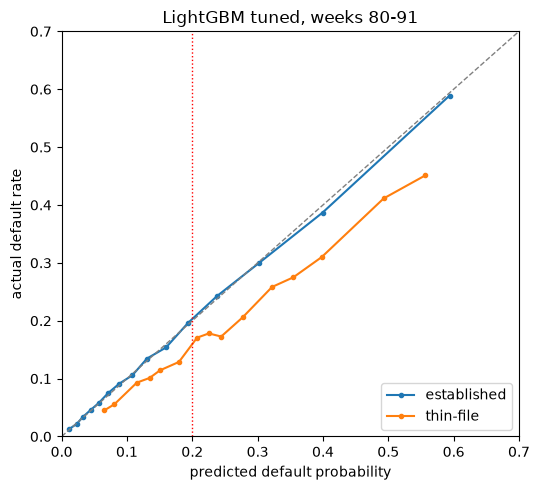

In [11]:
# Plot predicted vs actual default rate per segment for the tuned LightGBM.

def reliability_plot(ax, p, title):
    for seg, label in [(0, "established"), (1, "thin-file")]:
        m = thin_all[VA] == seg
        frac, mean_pred = calibration_curve(y_all[VA][m], p[m], n_bins=15, strategy="quantile")
        ax.plot(mean_pred, frac, marker="o", ms=3, label=label)
    ax.plot([0, 0.7], [0, 0.7], color="grey", ls="--", lw=1)
    ax.axvline(CUTOFF, color="red", ls=":", lw=1)
    ax.set(xlabel="predicted default probability", ylabel="actual default rate", title=title, xlim=(0, 0.7), ylim=(0, 0.7))
    ax.legend()


fig, ax = plt.subplots(figsize=(5.5, 5))
reliability_plot(ax, p_lgb, "LightGBM tuned, weeks 80-91")
plt.tight_layout(); plt.show()

**What this shows:** the blue (established) line sits on the diagonal, so those probabilities are accurate. The orange (thin-file)
line sits **below** it. For example, thin-file applicants predicted at ~30% actually default ~20% of the time. Many creditworthy thin-file
applicants are pushed over the red 20% cutoff and declined. That's the inclusion gap.

## 8. Fix 1: per-segment calibration

The model's ranking is fine; its thin-file *level* is stale because of the drift. A small correction per segment re-aligns it:
- Use the early-stopping model trained on weeks 0-67 (`lgb_early`, §4). It has **never seen** weeks 68-79.
- On weeks 68-79, fit a **Platt scaling** (a 2-parameter logistic correction of the model's log-odds) separately for thin-file and
  established applicants. Two parameters per segment can't overfit 160k rows (isotonic regression would be more flexible, but noisier).
- Apply the same correction to that model's predictions on weeks 80-91.

**Fairness note:** this uses `thin_file` when *converting* scores to probabilities, not as a model feature. This is the
"calibrated segment policy" in technical report §12, and it should be discussed with the team before adoption.

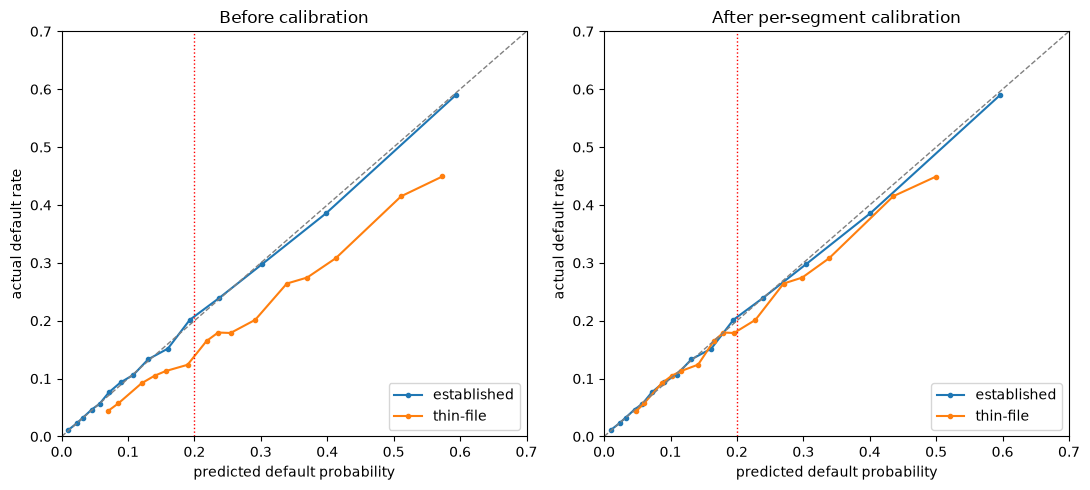

In [12]:
# Fix 1: learn a small probability correction per segment on weeks 68-79, apply it to weeks 80-91.

def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)


def fit_segment_calibration(p, y, thin):
    return {seg: LogisticRegression(C=1e6).fit(logit(p[thin == seg]), y[thin == seg]) for seg in (0, 1)}


def apply_segment_calibration(cal, p, thin):
    out = p.copy()
    for seg, model in cal.items():
        m = thin == seg
        out[m] = model.predict_proba(logit(p[m]))[:, 1]
    return out


p_early_tune = lgb_early.predict(X_all[TU], num_iteration=lgb_early.best_iteration)
p_early_val = lgb_early.predict(X_all[VA], num_iteration=lgb_early.best_iteration)
calibrators = fit_segment_calibration(p_early_tune, y_all[TU], thin_all[TU])
p_lgb_cal = apply_segment_calibration(calibrators, p_early_val, thin_all[VA])

results["LightGBM weeks 0-67 (uncalibrated)"] = evaluate(y_all[VA], p_early_val, thin_all[VA])
results["LightGBM + segment calibration"] = evaluate(y_all[VA], p_lgb_cal, thin_all[VA])

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
reliability_plot(axes[0], p_early_val, "Before calibration")
reliability_plot(axes[1], p_lgb_cal, "After per-segment calibration")
plt.tight_layout(); plt.show()

**What this shows:** after the per-segment correction, both lines sit on the diagonal. Thin-file over-prediction drops from 6.6 to
1.3 points. The model's ordering of applicants within each segment is unchanged; only the probability *level* is corrected.

## 9. Fix 2: recency weighting

Instead of correcting afterwards, let the model **learn more from recent weeks** during training. Each row gets weight
`0.5 ** ((last_week - week) / half_life)`: a row `half_life` weeks old counts half as much as the newest row.
`WEEK_NUM` is used only as a *weight*, never as a feature (test weeks 92+ lie outside the training range).

The half-life is chosen on the tune weeks (models trained on 0-67), from a small fixed set, so validation is still untouched.

In [13]:
# Fix 2, part 1: choose how strongly to favour recent weeks, using the tune weeks only.

def recency_weights(weeks, last_week, half_life):
    return np.ones(len(weeks)) if half_life is None else 0.5 ** ((last_week - weeks) / half_life)


half_life_scores = {}
for hl in [None, 52, 26, 13]:
    d = lgb.Dataset(X_all[TR], y_all[TR], weight=recency_weights(week[TR], TUNE_START_WEEK - 1, hl),
                    params={"feature_pre_filter": False})
    b = lgb.train(LGB_PARAMS, d, num_boost_round=5000, valid_sets=[lgb.Dataset(X_all[TU], y_all[TU], reference=d)],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
    p_tu = b.predict(X_all[TU], num_iteration=b.best_iteration)
    half_life_scores[str(hl)] = {"tune_logloss": log_loss(y_all[TU], p_tu), "tune_auc": roc_auc_score(y_all[TU], p_tu),
                                 "trees": b.best_iteration, "booster": b}

hl_table = pd.DataFrame(half_life_scores).T.drop(columns="booster")
BEST_HL = hl_table["tune_logloss"].astype(float).idxmin()
print(f"chosen half-life: {BEST_HL} weeks")
hl_table

chosen half-life: 13 weeks


,tune_logloss,tune_auc,trees
None,0.396188,0.772724,280
52,0.395608,0.773269,263
26,0.395188,0.773734,269
13,0.394669,0.774256,136


**What this shows:** the more the model favours recent weeks, the better it scores on the tune weeks. The shortest half-life tried
(13 weeks) won, so the drift is strong and recent history matters most. Shorter half-lives are worth testing in #14.

In [14]:
# Fix 2, part 2: train the recency-weighted model, on its own and combined with Fix 1.

hl = None if BEST_HL == "None" else int(BEST_HL)
hl_trees = int(half_life_scores[BEST_HL]["trees"])

# (a) weighted model retrained on weeks 0-79, weights relative to week 79
lgb_recency = lgb.train(LGB_PARAMS, lgb.Dataset(X_all[FIT], y_all[FIT], weight=recency_weights(week[FIT], VALID_START_WEEK - 1, hl)),
                        num_boost_round=hl_trees)
p_lgb_rec = lgb_recency.predict(X_all[VA])
results["LightGBM + recency weighting"] = evaluate(y_all[VA], p_lgb_rec, thin_all[VA])

# (b) both fixes: weighted model trained on 0-67, calibrated per segment on 68-79
b_rec_early = half_life_scores[BEST_HL]["booster"]
cal_rec = fit_segment_calibration(b_rec_early.predict(X_all[TU], num_iteration=b_rec_early.best_iteration), y_all[TU], thin_all[TU])
p_lgb_rec_cal = apply_segment_calibration(cal_rec, b_rec_early.predict(X_all[VA], num_iteration=b_rec_early.best_iteration), thin_all[VA])
results["LightGBM + recency + calibration"] = evaluate(y_all[VA], p_lgb_rec_cal, thin_all[VA])

## 10. Results: every model on weeks 80-91

Probability metrics and decision metrics side by side. **Profit** and **inclusion gap** use the challenge's 20% break-even cutoff.

In [15]:
# Collect every model's results into one table: probability quality.

res = pd.DataFrame(results).T
res.to_csv(ART / "results_valid_weeks_80_91.csv")

quality = res[["AUC", "AUC thin", "AUC est", "LogLoss", "LogLoss thin", "Brier", "Pred-actual thin pp", "Pred-actual est pp"]]
quality.round(4)

,AUC,AUC thin,AUC est,LogLoss,LogLoss thin,Brier,Pred-actual thin pp,Pred-actual est pp
LogReg (05 baseline),0.7597,0.7082,0.7856,0.3980,0.4673,0.1241,6.4011,-0.0520
LightGBM untuned (Krish-style),0.7682,0.7064,0.7944,0.3924,0.4639,0.1226,5.6011,0.0806
LightGBM tuned,0.7679,0.7065,0.7940,0.3925,0.4637,0.1227,5.5515,0.0389
XGBoost tuned,0.7677,0.7063,0.7941,0.3925,0.4638,0.1226,5.5929,0.0105
Ensemble LightGBM+XGBoost,0.7679,0.7064,0.7942,0.3924,0.4637,0.1226,5.5722,0.0247
LightGBM weeks 0-67 (uncalibrated),0.7669,0.7071,0.7939,0.3937,0.4673,0.1231,6.6439,0.0304
LightGBM + segment calibration,0.7705,0.7071,0.7939,0.3898,0.4545,0.1216,1.2924,0.1471
LightGBM + recency weighting,0.7698,0.7080,0.7937,0.3904,0.4562,0.1218,2.9397,0.1444
LightGBM + recency + calibration,0.7705,0.7081,0.7937,0.3898,0.4543,0.1216,1.4117,0.1779


In [16]:
# Same models: decision metrics at the 20% cutoff.

decision = res[["Accuracy@20%", "F1@20%", "Approval %", "Default % approved", "Profit $M",
                "Approved repayers est %", "Approved repayers thin %", "Gap@20% pp", "Gap@70% approval pp"]]
decision.round(3)

,Accuracy@20%,F1@20%,Approval %,Default % approved,Profit $M,Approved repayers est %,Approved repayers thin %,Gap@20% pp,Gap@70% approval pp
LogReg (05 baseline),0.678,0.433,60.512,8.321,92.186,78.105,40.267,37.838,28.603
LightGBM untuned (Krish-style),0.690,0.442,61.885,8.237,94.958,78.244,45.396,32.848,22.623
LightGBM tuned,0.691,0.442,62.051,8.269,94.950,78.090,46.323,31.767,23.091
XGBoost tuned,0.689,0.441,61.744,8.263,94.530,78.316,44.612,33.703,23.927
Ensemble LightGBM+XGBoost,0.690,0.442,61.858,8.243,94.866,78.179,45.434,32.744,23.488
LightGBM weeks 0-67 (uncalibrated),0.686,0.440,61.306,8.200,94.366,78.173,43.445,34.728,25.487
LightGBM + segment calibration,0.725,0.452,67.117,8.938,96.846,77.904,64.286,13.619,12.551
LightGBM + recency weighting,0.707,0.447,64.305,8.535,96.170,77.810,54.918,22.893,15.681
LightGBM + recency + calibration,0.725,0.452,67.064,8.915,96.968,78.132,63.592,14.540,12.306


**How to read these two tables:** compare each row with the logistic-regression baseline on the first line.
- *Quality table:* AUC up = better ranking; LogLoss / Brier down = more accurate probabilities; `Pred-actual` near 0 = honest probabilities.
- *Decision table:* higher profit is better; a smaller `Gap@20% pp` means thin-file repayers are treated more like established ones.
  `Default % approved` must stay under the challenge's default-rate ceiling.

The calibrated LightGBM rows stand out: the gap roughly halves (31.8 → 13.6 pp) and profit rises (+$1.9M).

## 11. Useful analysis

### 11a. Profit and inclusion gap across cutoffs
The 20% cutoff is only break-even for a *perfectly calibrated* model. This shows how profit and the gap move as the cutoff
changes, for the tuned model and the calibrated one. It's the input the policy work (segment-aware thresholds, default-rate ceiling) will need.

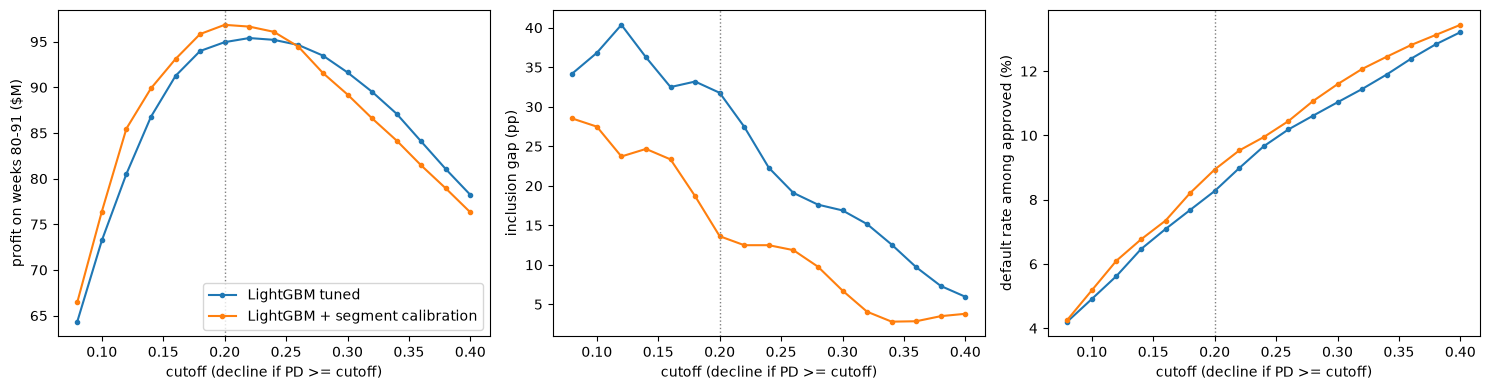

In [17]:
# How profit, inclusion gap and default rate change if the cutoff moves away from 20%.

cutoffs = np.round(np.arange(0.08, 0.42, 0.02), 2)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name, p in [("LightGBM tuned", p_lgb), ("LightGBM + segment calibration", p_lgb_cal)]:
    rows = [evaluate(y_all[VA], p, thin_all[VA], cutoff=c) for c in cutoffs]
    axes[0].plot(cutoffs, [r["Profit $M"] for r in rows], marker="o", ms=3, label=name)
    axes[1].plot(cutoffs, [r["Gap@20% pp"] for r in rows], marker="o", ms=3, label=name)
    axes[2].plot(cutoffs, [r["Default % approved"] for r in rows], marker="o", ms=3, label=name)
for ax, ylab in zip(axes, ["profit on weeks 80-91 ($M)", "inclusion gap (pp)", "default rate among approved (%)"]):
    ax.axvline(CUTOFF, color="grey", ls=":", lw=1)
    ax.set(xlabel="cutoff (decline if PD >= cutoff)", ylabel=ylab)
axes[0].legend(); plt.tight_layout(); plt.show()

**What this shows:** with calibration (orange), profit peaks right at the 20% break-even cutoff, as theory says it should for
honest probabilities. Without it (blue), the best cutoff drifts away from 20%. At every cutoff, the calibrated model has a smaller inclusion
gap, at the cost of a slightly higher default rate among approved loans.

### 11b. Stability week by week
A credit model has to hold up as time passes. AUC per validation week and segment for the tuned LightGBM:

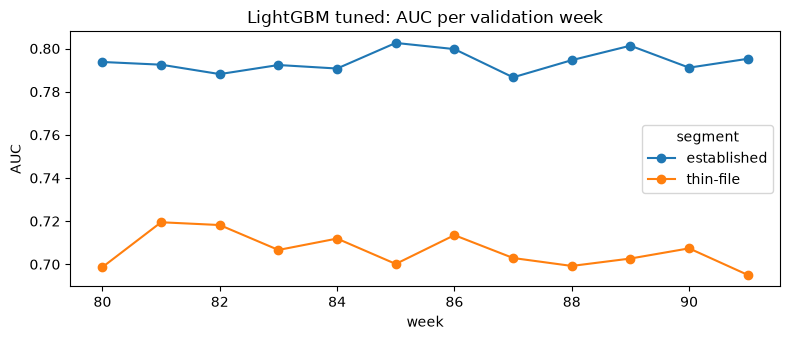

segment,established,thin-file
mean,0.7941,0.7063
std,0.0050,0.0080
min,0.7867,0.6951
max,0.8026,0.7195


In [18]:
# AUC for each validation week, to check the model holds up over time.

weekly = []
for w in np.unique(week[VA]):
    m = week[VA] == w
    for seg, label in [(0, "established"), (1, "thin-file")]:
        s = m & (thin_all[VA] == seg)
        weekly.append({"week": w, "segment": label, "AUC": roc_auc_score(y_all[VA][s], p_lgb[s])})
weekly = pd.DataFrame(weekly).pivot(index="week", columns="segment", values="AUC")
ax = weekly.plot(marker="o", figsize=(8, 3.5), title="LightGBM tuned: AUC per validation week")
ax.set_ylabel("AUC"); plt.tight_layout(); plt.show()
weekly.agg(["mean", "std", "min", "max"]).round(4)

**What this shows:** week-to-week AUC varies by only ~0.005 (established) and ~0.008 (thin-file), with no downward trend across
weeks 80-91. The model's ranking is stable; what drifts over time is the thin-file *probability level*, which calibration handles.

### 11c. What the model relies on, overall and per segment
- **Gain importance:** how much each feature reduced the loss across all splits.
- **SHAP (per segment):** average absolute contribution of each feature to individual predictions, computed separately for
  thin-file and established applicants (20k sampled each). This shows which features actually drive *thin-file* decisions.

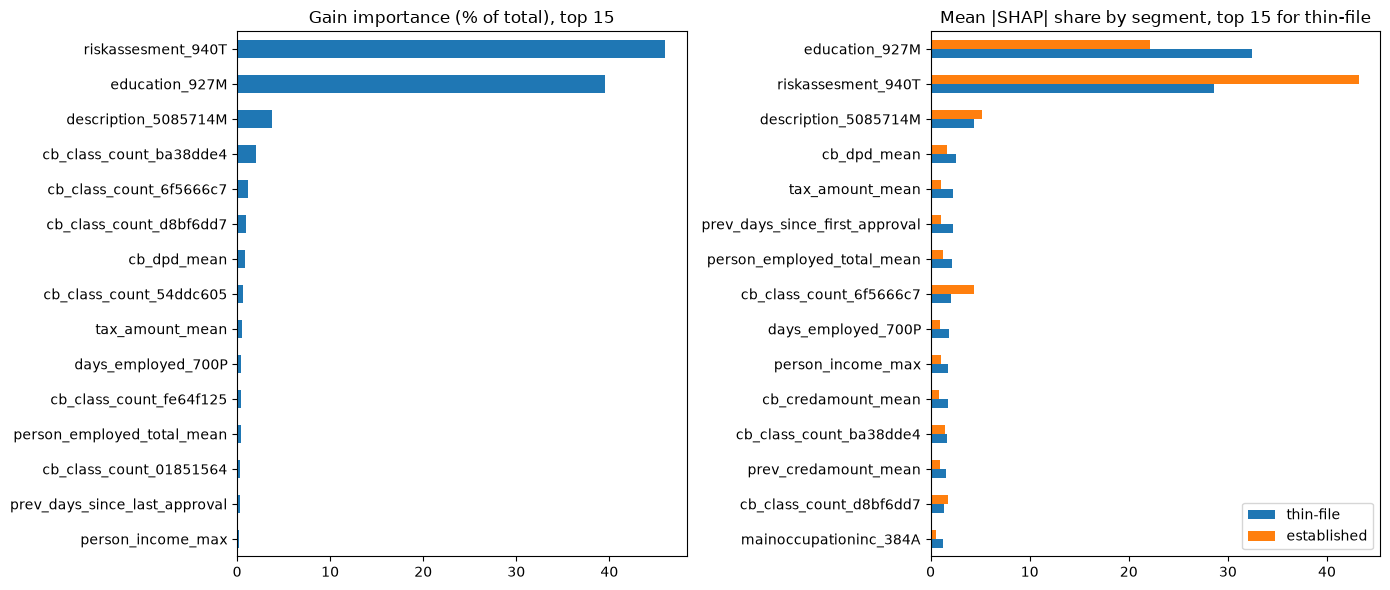

In [19]:
# Which features drive predictions: overall (gain) and per segment (SHAP).

gain = pd.Series(lgb_final.feature_importance("gain"), index=FEATURES)
gain = (gain / gain.sum() * 100).sort_values(ascending=False)

sample = {}
for seg, label in [(1, "thin-file"), (0, "established")]:
    idx = np.flatnonzero(VA & (thin_all == seg))
    pick = np.random.default_rng(SEED).choice(idx, size=min(20_000, len(idx)), replace=False)
    contrib = lgb_final.predict(X_all.iloc[pick], pred_contrib=True)[:, :-1]   # last column = bias
    sample[label] = np.abs(contrib).mean(axis=0)
shap_seg = pd.DataFrame(sample, index=FEATURES)
shap_seg = (shap_seg / shap_seg.sum() * 100).sort_values("thin-file", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
gain.head(15)[::-1].plot.barh(ax=axes[0], title="Gain importance (% of total), top 15")
shap_seg.head(15)[::-1].plot.barh(ax=axes[1], title="Mean |SHAP| share by segment, top 15 for thin-file")
plt.tight_layout(); plt.show()

**Reading the SHAP chart:** `riskassesment_940T` (the bureau risk score) and the `cb_*` features have large effects for **thin-file
applicants, who don't have them at all**. The model has learned that *a missing bureau score* means higher risk, so being thin-file is
penalized through missingness even though `thin_file` itself isn't a feature. That's the mechanism behind the inclusion gap, and why
removing the `thin_file` column alone doesn't make scoring neutral. `education_927M` is the strongest feature that every applicant actually has.

## 12. Save artifacts for Task #4 and #14

| File | For |
|---|---|
| `best_params.json` | chosen settings, tree counts, selection rule, chosen half-life (#14 starts from here) |
| `results_valid_weeks_80_91.csv` | the comparison table above (Task #4) |
| `tuning_lightgbm.csv`, `tuning_xgboost.csv` | every trial, for Skylar's tuning |
| `lightgbm_final.txt`, `xgboost_final.json` | trained models (weeks 0-79) |
| `predictions_valid.parquet`, `predictions_test.parquet` | `case_id`, `thin_file`, PD from each model, for policy/inclusion-gap work |

The test predictions are **scores only**: `solution.csv` is never opened here.

In [20]:
# Save settings, tables, models and predictions so other tasks can reuse them.

lgb_tuning.to_csv(ART / "tuning_lightgbm.csv", index=False)
xgb_tuning.to_csv(ART / "tuning_xgboost.csv", index=False)
lgb_final.save_model(str(ART / "lightgbm_final.txt"))
xgb_final.save_model(str(ART / "xgboost_final.json"))

to_py = lambda d: {k: (v.item() if hasattr(v, "item") else v) for k, v in d.items()}
json.dump({
    "split": {"train_weeks": "0-67", "tune_weeks": "68-79", "valid_weeks": "80-91", "final_fit_weeks": "0-79"},
    "selection": f"lowest tune LogLoss; ties within {TIE_TOLERANCE} broken by simplest model",
    "lightgbm": {"params": to_py(LGB_PARAMS), "trees": LGB_TREES},
    "xgboost": {"params": to_py({**XGB_BASE, **XGB_PARAMS}), "trees": XGB_TREES},
    "ensemble": {"method": "soft voting, 50/50 average of LightGBM and XGBoost probabilities",
                 "recommended": ENSEMBLE_RECOMMENDED},
    "recency_half_life_weeks": BEST_HL, "recency_trees": hl_trees,
    "excluded_from_features": NOT_FEATURES,
}, open(ART / "best_params.json", "w"), indent=2)

meta_va = train_df.loc[VA, ["case_id", "WEEK_NUM", "thin_file", "target"]].reset_index(drop=True)
pd.concat([meta_va, pd.DataFrame({
    "pd_lightgbm": p_lgb, "pd_xgboost": p_xgb, "pd_ensemble": p_blend,
    "pd_lightgbm_calibrated": p_lgb_cal, "pd_lightgbm_recency": p_lgb_rec,
})], axis=1).to_parquet(ART / "predictions_valid.parquet", index=False)

p_test_early = lgb_early.predict(X_test, num_iteration=lgb_early.best_iteration)
pd.DataFrame({
    "case_id": test_df["case_id"], "WEEK_NUM": test_df["WEEK_NUM"], "thin_file": test_df["thin_file"],
    "pd_lightgbm": lgb_final.predict(X_test),
    "pd_xgboost": xgb_final.predict_proba(X_test)[:, 1],
    "pd_ensemble": (lgb_final.predict(X_test) + xgb_final.predict_proba(X_test)[:, 1]) / 2,
    "pd_lightgbm_calibrated": apply_segment_calibration(calibrators, p_test_early, test_df["thin_file"].to_numpy()),
}).to_parquet(ART / "predictions_test.parquet", index=False)

print("saved:", sorted(p.name for p in ART.iterdir()))

saved: ['best_params.json', 'lightgbm_final.txt', 'predictions_test.parquet', 'predictions_valid.parquet', 'results_valid_weeks_80_91.csv', 'tuning_lightgbm.csv', 'tuning_xgboost.csv', 'xgboost_final.json']


## 13. Conclusions (Issue #13: gradient boosting)

All numbers are on the untouched validation weeks 80-91, cutoff 20%.

| | AUC | AUC thin | LogLoss | Brier | Acc@20% | F1@20% | Profit | Inclusion gap |
|---|---|---|---|---|---|---|---|---|
| Logistic regression (baseline) | 0.760 | 0.708 | 0.398 | 0.124 | 0.678 | 0.433 | $92.2M | 37.8 pp |
| LightGBM tuned | 0.768 | 0.707 | 0.393 | 0.123 | 0.691 | 0.442 | $95.0M | 31.8 pp |
| XGBoost tuned | 0.768 | 0.706 | 0.393 | 0.123 | 0.689 | 0.441 | $94.5M | 33.7 pp |
| Ensemble LightGBM + XGBoost | 0.768 | 0.706 | 0.392 | 0.123 | 0.690 | 0.442 | $94.9M | 32.7 pp |
| LightGBM + recency weighting | 0.770 | 0.708 | 0.390 | 0.122 | 0.707 | 0.447 | $96.2M | 22.9 pp |
| **LightGBM + per-segment calibration** | **0.771** | 0.707 | **0.390** | **0.122** | **0.725** | **0.452** | **$96.8M** | **13.6 pp** |
| LightGBM + recency + calibration | 0.771 | 0.708 | 0.390 | 0.122 | 0.725 | 0.452 | $97.0M | 14.5 pp |

1. **Gradient boosting beats the logistic-regression baseline** on every quality metric (AUC +0.008, LogLoss −0.006), earning **+$2.8M**
   and a 6 pp smaller inclusion gap, as the challenge requires.
2. **Tuning barely matters, and nothing is overfitting.** 28 of 30 settings tied; the tuned model equals the untuned one. The chosen
   settings are the most conservative ones, which is the safest choice for later weeks.
3. **The ensemble isn't worth it.** LightGBM and XGBoost agree at 0.997 correlation and on 97.8% of decisions; the ensemble improves
   LogLoss by only 0.0001 (noise) and slightly widens the gap. **Use LightGBM alone.**
4. **The thin-file problem is calibration, not ranking.** Every model over-predicts thin-file default risk by ~5.5 pp. Per-segment
   calibration on the latest weeks cuts that to 1.3 pp, which **cuts the inclusion gap from 31.8 to 13.6 pp (−57%) while raising profit by
   $1.9M**. Approved thin-file repayers go from 46% to 64%. The trade-off: the default rate among approved rises from 8.3% to 8.9%, which
   must stay under the challenge's default-rate ceiling.
5. **Recency weighting helps on its own** (gap 22.9 pp, +$1.2M), but adds nothing on top of calibration.
6. **Thin-file ranking is stuck at AUC ≈ 0.707** for every model. Better *ordering* of thin-file applicants needs new information
   (features), not a different algorithm.

### Recommendation for Task #4 (candidate model choice)
**LightGBM (settings in `artifacts/best_params.json`) + per-segment calibration** as the gradient-boosting candidate. Two points for the
group discussion:
- Calibration uses `thin_file` when converting scores to probabilities (technical report §12, "calibrated segment policy"). Agree as a
  team that this is acceptable.
- The overall AUC rises with calibration (0.767 → 0.771) only because it re-orders applicants *across* segments. Within each segment
  the ranking is unchanged.

### Notes for #14 (hyper-parameter tuning)
- Start from `best_params.json`. The search space is flat, so don't expect big gains; optimize **thin-file LogLoss** on weeks 68-79, never on 80-91.
- The best recency half-life (13 weeks) was the shortest one tried. Test shorter half-lives (4-8 weeks) and a lower learning rate (0.02).
- Re-check calibration after any change: it matters more for profit and inclusion than the tree settings do.